<div>
    <a href="../notebook/__1_data_understanding.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white;">Previous</a>
    <a href="../notebook/__3_data_modeling.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>

## Section 2 | Data Analysis
---

In [1]:
# import required library

# data ETL
import pandas as pd
from utils import convert_categorical_variable

# data analysis
import matplotlib.pyplot as plt
import seaborn as sns

### Data ETL

In [2]:
# data ETL
data = pd.read_csv(
    filepath_or_buffer='../data/data_cleaned.csv'
)

# data cleaning
data = convert_categorical_variable(
    categorical_variables=['cylinders', 'model_year', 'origin'],
    data=data
)

# show first 5 rows of cleaned data
data.head(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


### Univariate Analysis
---
#### Tabular Analysis

In [3]:
# generate descriptive statistics from numerical variables in the dataset
data.describe(include='number' )

,displacement,horsepower,weight,acceleration,mpg
count,392.000000,392.000000,392.000000,392.000000,392.000000
mean,194.411990,104.469388,2977.584184,15.541327,23.445918
std,104.644004,38.491160,849.402560,2.758864,7.805007
min,68.000000,46.000000,1613.000000,8.000000,9.000000
25%,105.000000,75.000000,2225.250000,13.775000,17.000000
50%,151.000000,93.500000,2803.500000,15.500000,22.750000
75%,275.750000,126.000000,3614.750000,17.025000,29.000000
max,455.000000,230.000000,5140.000000,24.800000,46.600000


**Observations:**
* The exact numerical statistics of `numerical_variables` are provided above in tabular format:
    * `count` refers to the number of non-null values for each columns (similar with `Row/Instance` values in previous `Section 1: Initial Data Audit`),
    * `mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values over each columns,
    * `std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variables,
    * `min` and `max` are the minimum and maximum of the values in each columns, respectively, and
    * `25%`, `50%` and `75%` are the corresponding [percentiles](https://en.wikipedia.org/wiki/Percentile) (`50%` percentile juga bisa disebut dengan [median](https://en.wikipedia.org/wiki/Median))
* `mean` and `50%` (median) values for each variables mengindikasikan bahwa `numerical_variables` tersebut tidak ada yang [berdistribusi normal](https://en.wikipedia.org/wiki/Normal_distribution), karena karakteristik dari distribusi normal is symmetric around the $µ$ parameter, which is at the same time the mean, median, and the mode (for discrete categorical variable) of the distribution —a.k.a. the values must be equal for each of them.
* Additional inferences may be provided from visual & statistical analysis below.

In [4]:
# generate descriptive statistics from categorical variables in the dataset
data.describe(include='object')

,cylinders,model_year,origin
count,392,392,392
unique,5,13,3
top,4,73,1
freq,199,40,245


**Observations:**

* Selain `count` yang serupa pada analisis `numerical_variables` sebelumnya, fungsi `describe()` untuk `categorical_variables` menunjukkan hal-hal berikut:
    1. `unique` returns distinct values in each columns,
    2. `top` is the most common value in the variable, and
    3. `freq` represents the most common value`s frequency.
* Nilai `unique` pada kolom `model_year` sejumlah `13` yang bernilai relatif lebih besar daripada kolom lainnya mengindikasikan adanya permasalahan [kardinalitas](https://en.wikipedia.org/wiki/Cardinality_(SQL_statements)).

#### Visual Analysis

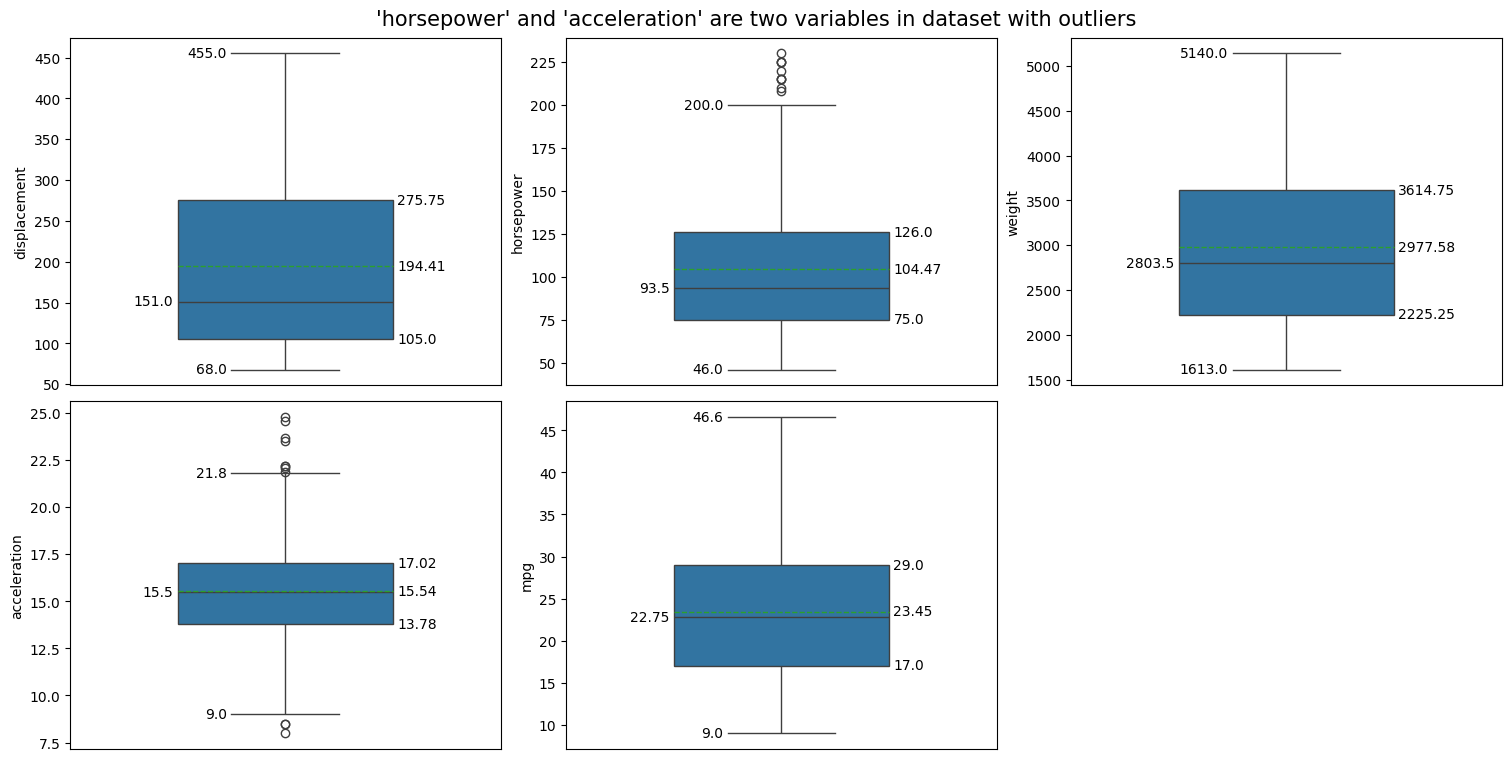

In [24]:
# subset columns with numerical data types from dataset
data_numerical = data.select_dtypes(include='number')

# create & setup plot figure
plt.figure(
    figsize=(15, 7.5),
    layout='constrained'
)
plt.suptitle(
    t="'horsepower' and 'acceleration' are two variables in dataset with outliers",
    size=15
)

# create boxplot for each numerical columns
for count, variable in enumerate(iterable=data_numerical):
    plt.subplot(2, 3, count + 1)
    boxplot = sns.boxplot(
        data=data,
        y=variable,
        width=0.5,
        showmeans=True,
        meanline=True
    )
    boxplot.set_xticks(ticks=list())

    # adding boxplot elements
    x_Q1, y_Q1 = boxplot.get_lines()[0].get_xydata()[0]
    boxplot.text(x=x_Q1 + 0.26, y=y_Q1, s=round(number=y_Q1, ndigits=2), verticalalignment='center', horizontalalignment='left')

    x_Q3, y_Q3 = boxplot.get_lines()[1].get_xydata()[0]
    boxplot.text(x=x_Q3 + 0.26, y=y_Q3, s=round(number=y_Q3, ndigits=2), verticalalignment='center', horizontalalignment='left')

    x_lower_bound, y_lower_bound = boxplot.get_lines()[2].get_xydata()[0]
    boxplot.text(x=x_lower_bound - 0.01, y=y_lower_bound, s=round(y_lower_bound, 2), verticalalignment='center', horizontalalignment='right')

    x_upper_bound, y_upper_bound = boxplot.get_lines()[3].get_xydata()[0]
    boxplot.text(x=x_upper_bound - 0.01, y=y_upper_bound, s=round(y_upper_bound, 2), verticalalignment='center', horizontalalignment='right')

    x_median, y_median = boxplot.get_lines()[4].get_xydata()[0]
    boxplot.text(x=x_median - 0.01, y=y_median, s=round(number=y_median, ndigits=2), verticalalignment='center', horizontalalignment='right')

    x_mean, y_mean = boxplot.get_lines()[5].get_xydata()[0]
    boxplot.text(x=x_mean + 0.51, y=y_mean, s=round(number=y_mean, ndigits=2), verticalalignment='center', horizontalalignment='left')

[Box plot](https://en.wikipedia.org/wiki/Box_plot) is a method for demonstrating graphically the locality, spread and skewness of numerical data through their quartiles. Components of the plot are as follows:
* The box by itself illustrates the interquartile spread of the distribution.
    * Its length is determined by the $25^{th}\;(Q1)$ and $75^{th}\;(Q3)$ percentiles.
    * Untuk contoh kolom `displacement` di atas, `Q1` dan `Q3` masing-masing bernilai `105.0` dan `275.75`.
* The horizontal line inside the box marks the median ($50\%$) of the distribution.
    * Pada variabel `horsepower`, median dari variabel ini adalah `93.5`.
    * Sebagai tambahan, dotted lines inside the box marks the mean of the distribution.
* The whiskers are the lines extending from the box.
    * They represent the entire scatter of data points.
    * Specifically the points that fall within the interval $Q1-(1.5\;x\;IQR),\;Q3+(1.5\;x\;IQR)$, where $IQR=Q3-Q1$ as the interquartile range.
* Outliers that fall outside of the range bounded by the whiskers are plotted individually as black points along the central axis.
    * Pada contoh `acceleration`, data di atas nilai `21.8` merupakan outlier pada variabel ini.
    * Dan tampak bahwa dua variabel `horsepower` dan `acceleration` yang memiliki outlier dari keseluruhan variabel numerik dalam dataset.

<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| Variable Magnitude | Variable magnitude issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| **Outlier** | **Outlier issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |

</center>

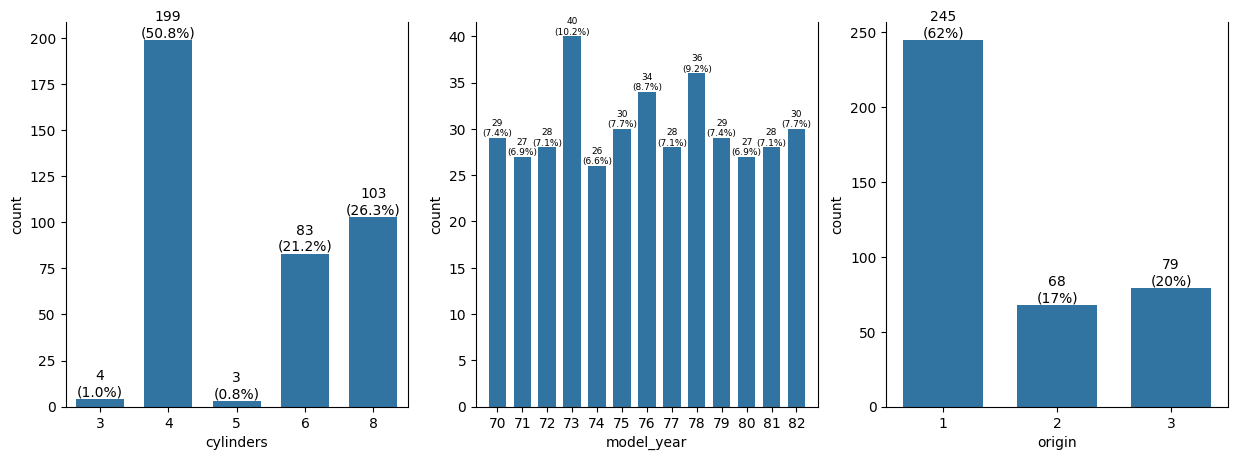

In [6]:
plt.figure(figsize=(15, 5))

data_categorical = data.select_dtypes(include='object')

def plot_univariate_categorical(source=data_categorical, ndigits=None, label_type='edge', fontsize=10):
    plt.subplot(1, 3, count + 1)

    barplot_data = pd.concat(
        objs=[source[variable].value_counts().sort_index(),
              source[variable].value_counts(normalize=True).mul(other=100)],
        axis=1
    )

    axes = sns.barplot(
        data=barplot_data, 
        x=barplot_data.index,
        y="count",
        width=0.7
    )

    labels = [f"{round(value.get_height())}\n({round(number=barplot_data.iloc[index, 1], ndigits=ndigits)}%)"
              for index, value in enumerate(axes.containers[0])]
    
    axes.bar_label(
        container=axes.containers[0], 
        labels=labels, 
        label_type=label_type,
        fontsize=fontsize
    )
    axes.spines.top.set_visible(b=False)

    return axes

for count, variable in enumerate(iterable=data_categorical):
    if variable == 'cylinders':
        plot_univariate_categorical(ndigits=1)

    elif variable == 'model_year':
        axes = plot_univariate_categorical(
            ndigits=1,
            fontsize=6.5
        )
        axes.margins(0.04)
        
    else:
        plot_univariate_categorical()

#### Statistical Analysis

In [7]:
from scipy.stats import norm, kstest, shapiro, normaltest
from statsmodels.stats.diagnostic import lilliefors

kstest_stat = list()
kstest_pval = list()

for variable in data_numerical.columns:

    variable_loc, variable_scale = norm.fit(data=data_numerical[variable])
    variable_norm = norm(loc=variable_loc, scale=variable_scale)

    kstest_stat.append(kstest(
        rvs=data_numerical[variable],
        cdf=variable_norm.cdf
    )[0])
    kstest_pval.append(kstest(
        rvs=data_numerical[variable], 
        cdf=variable_norm.cdf
    )[1])

pd.DataFrame(data={
    "skewness": data_numerical.apply(func=lambda variable: variable.skew()).values,
    "kurtosis": data_numerical.apply(func=lambda variable: variable.kurt()).values,
    "kstest_pval": kstest_pval,
    "lilliefors_pval": data_numerical.apply(lambda variable: lilliefors(x=variable)[1]).values,
    "shapiro_pval": data_numerical.apply(lambda variable: shapiro(x=variable)[1]).values,
    "normaltest_pval": data_numerical.apply(lambda variable: normaltest(a=variable)[1]).values
}).set_index(keys=data_numerical.columns)

,skewness,kurtosis,kstest_pval,lilliefors_pval,shapiro_pval,normaltest_pval
displacement,0.701669,-0.778317,8.601573e-12,0.001000,8.983637e-17,1.142372e-12
horsepower,1.087326,0.696947,1.223489e-09,0.001000,5.022069e-15,8.101947e-14
weight,0.519586,-0.809259,1.632845e-03,0.001000,2.601686e-11,3.833841e-11
acceleration,0.291587,0.444234,2.462328e-01,0.017079,3.052886e-02,1.648227e-02
mpg,0.457092,-0.515993,9.652916e-03,0.001000,1.049441e-07,3.605849e-05


<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| Variable Magnitude | Variable magnitude issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| Outlier | Outlier issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| **Normality** | **Normality issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |

</center>

### Multivariate Analysis
---
#### Numerical Variables

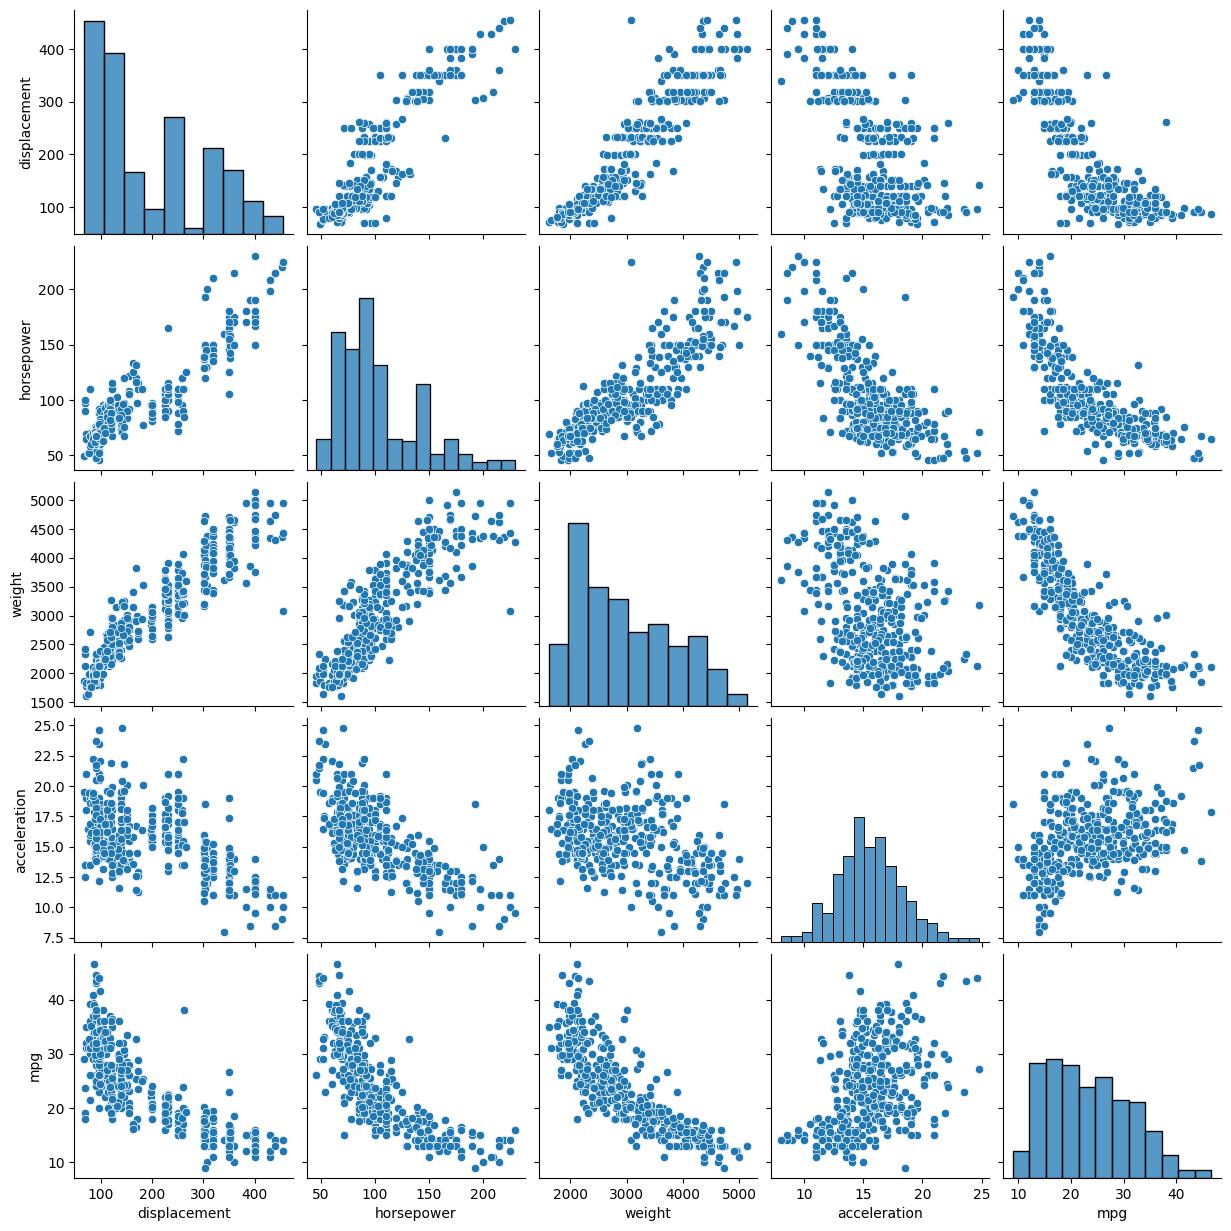

In [8]:
ax = sns.pairplot(data=data_numerical)

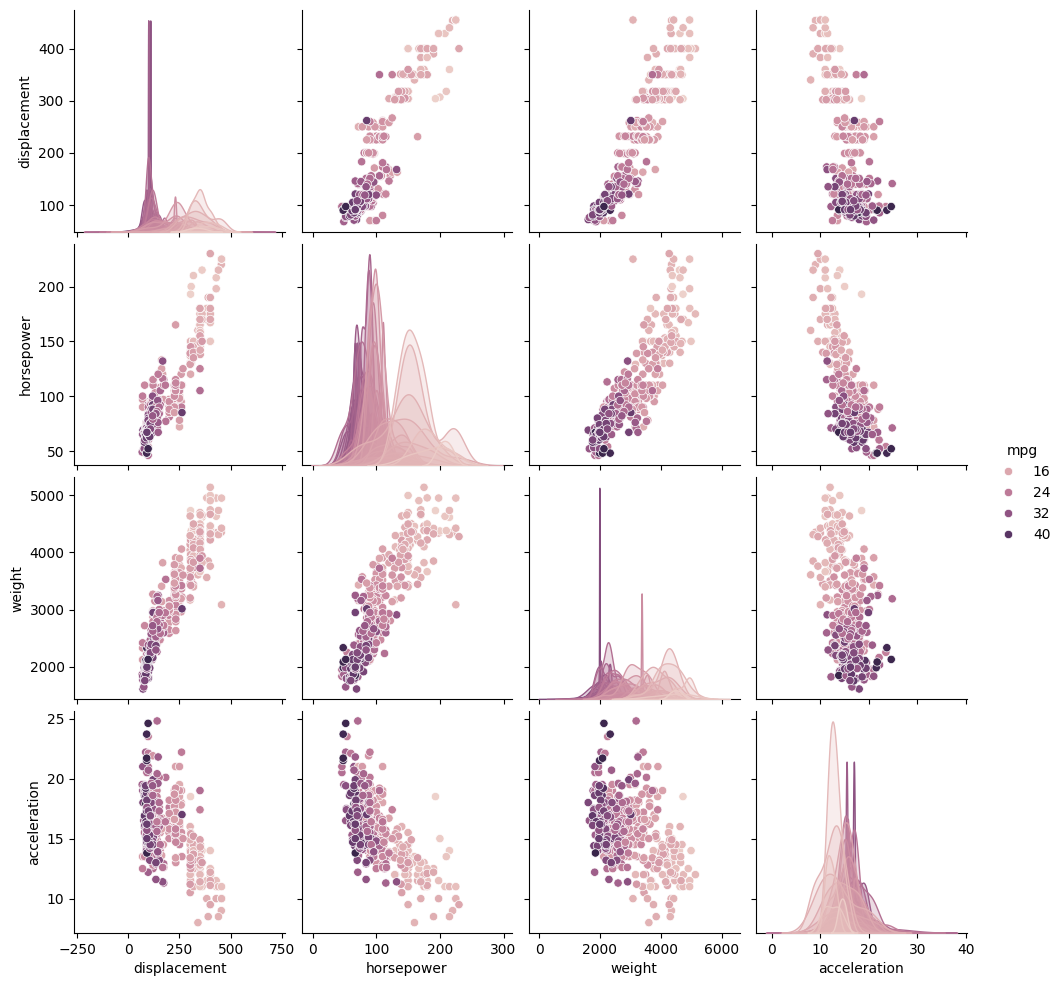

In [9]:
ax = sns.pairplot(
    data=data_numerical,
    hue='mpg'
)

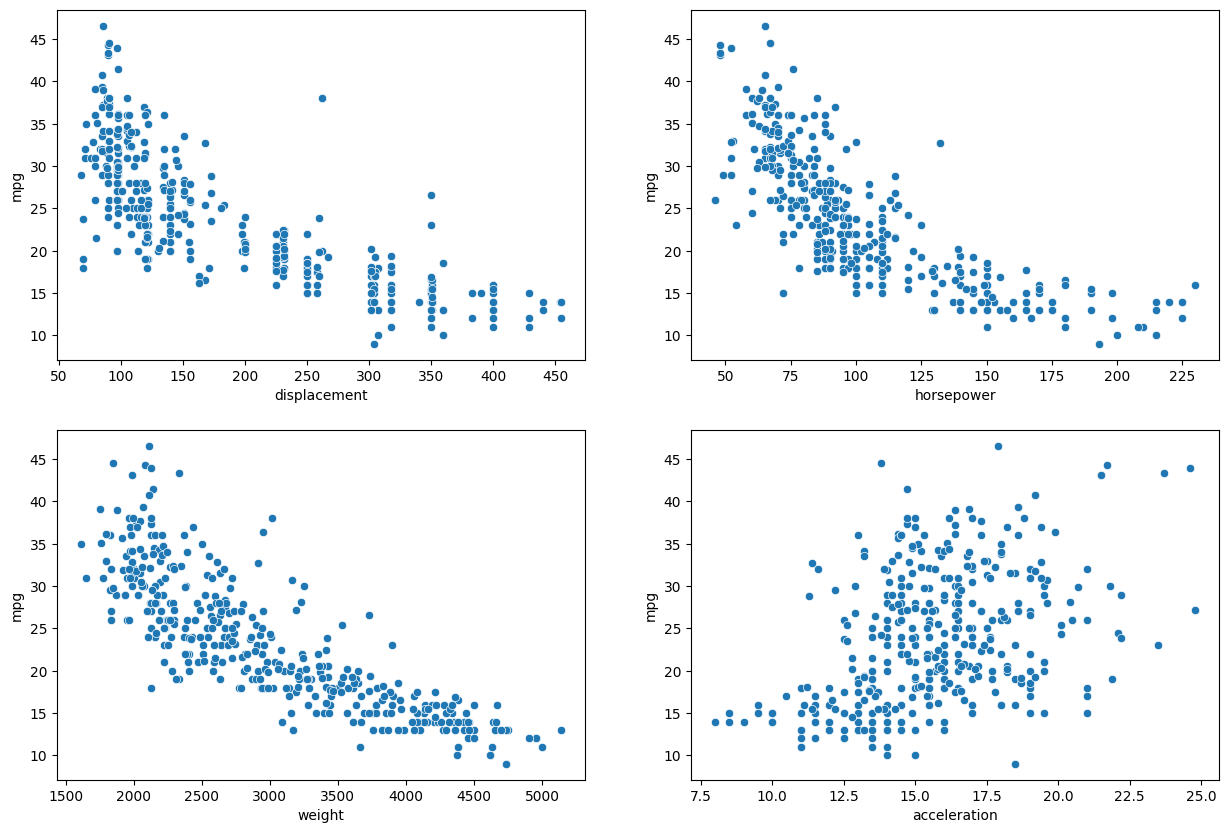

In [10]:
plt.figure(figsize=(15, 10))

numerical_variables = data_numerical.drop(columns='mpg')
target_variable = data_numerical['mpg']

for count, numerical_variable in enumerate(iterable=numerical_variables):
    plt.subplot(2, 2, count + 1)
    sns.scatterplot(
        data=data_numerical,
        x=numerical_variable,
        y=target_variable
    )

#### Categorical Variables

<div>
    <a href="../notebook/__1_business_and_data_understanding.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white;">Previous</a>
    <a href="../notebook/__3_data_modeling.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>